/var/folders/d6/kyp3t7sd195fq1mxczblbksm0000gn/T/ipykernel_53113/3338244709.py:22: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  plt.scatter(x1_train, x2_train, cmap='viridis', marker='x')


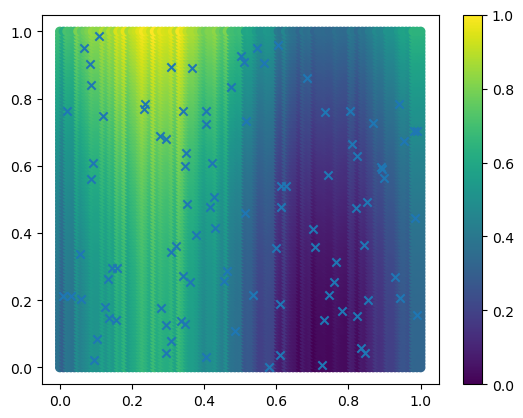

In [1]:
import numpy as np
import matplotlib.pyplot as plt

def gaussian(x):
    return np.exp(-x**2 / 2)
# Generate grid data for x1 and x2 (test data)
x1 = np.linspace(0, 1, 100)
x2 = np.linspace(0, 1, 100)
# Now compute the grid of x1 and x2 values
X1, X2 = np.meshgrid(x1, x2)

# Generate training data
x1_train = np.random.uniform(0, 1, 100)
x2_train = np.random.uniform(0, 1, 100)
y_train = np.sin(2 * np.pi * x1_train) + x2_train*x2_train + np.random.normal(0, 0.1, 100)

# Compute the true function values
y = np.sin(2 * np.pi * X1) + X2*X2 + np.random.normal(0, 0.1, 100)
# Now plot the true value and the kernel smoothed value
plt.scatter(X1, X2, c=y, cmap='viridis')
# Add the training data to the plot
plt.scatter(x1_train, x2_train, cmap='viridis', marker='x')
plt.colorbar();
plt.show()

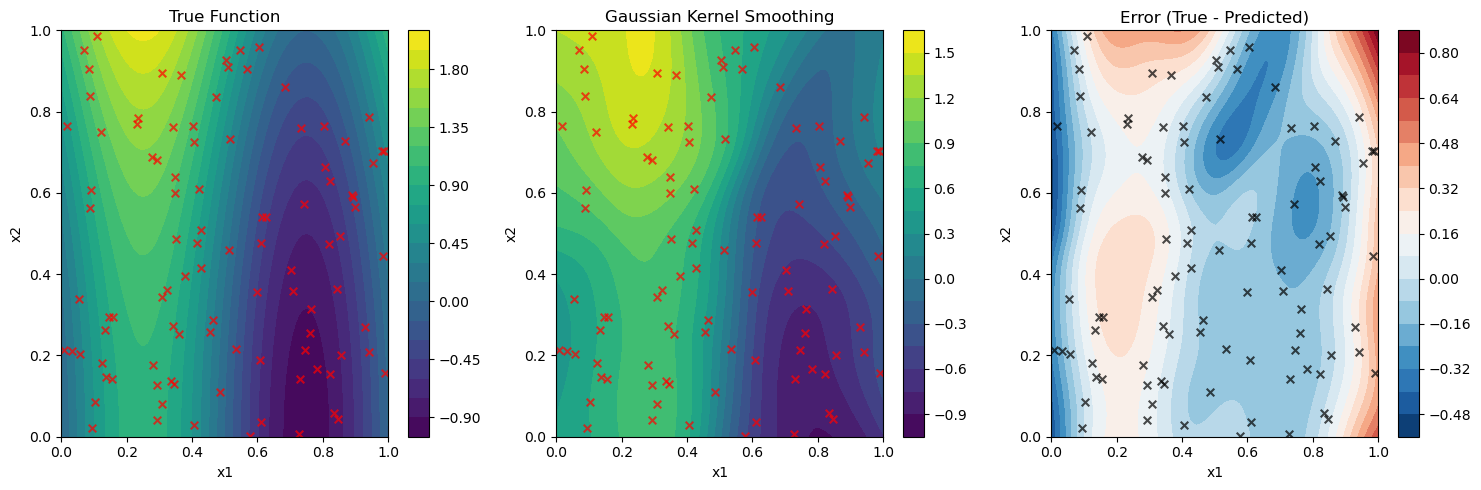

Mean Squared Error: 0.0419
Mean Absolute Error: 0.1707
Training data points: 100
Grid size: (100, 100)
Bandwidth used: 0.1


In [2]:
def gaussian_kernel_smoothing(X1, X2, x1_train, x2_train, y_train, bandwidth=0.1):
    """
    Perform Gaussian kernel smoothing to predict values at grid points (X1, X2).
    
    Parameters:
    - X1, X2: meshgrid arrays representing test points
    - x1_train, x2_train: training input coordinates
    - y_train: training target values
    - bandwidth: bandwidth parameter for the Gaussian kernel (sigma)
    
    Returns:
    - y_pred: predicted values at grid points with same shape as X1, X2
    """
    # Get the shape of the grid
    shape = X1.shape
    
    # Flatten the grid points for easier computation
    X1_flat = X1.flatten()
    X2_flat = X2.flatten()
    
    # Initialize predictions array
    y_pred_flat = np.zeros(len(X1_flat))
    
    # For each test point, compute weighted average using Gaussian kernel
    for i in range(len(X1_flat)):
        test_x1, test_x2 = X1_flat[i], X2_flat[i]
        
        # Compute distances from test point to all training points
        distances_squared = (x1_train - test_x1)**2 + (x2_train - test_x2)**2
        
        # Compute Gaussian weights
        weights = np.exp(-distances_squared / (2 * bandwidth**2))
        
        # Compute weighted average (kernel smoothing prediction)
        if np.sum(weights) > 0:
            y_pred_flat[i] = np.sum(weights * y_train) / np.sum(weights)
        else:
            y_pred_flat[i] = 0  # fallback if all weights are zero
    
    # Reshape back to grid shape
    y_pred = y_pred_flat.reshape(shape)
    
    return y_pred

# Test the function with the existing data
y_pred = gaussian_kernel_smoothing(X1, X2, x1_train, x2_train, y_train, bandwidth=0.1)

# Plot comparison between true function and kernel smoothing prediction
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

# True function (without noise for cleaner visualization)
y_true = np.sin(2 * np.pi * X1) + X2*X2

# Plot 1: True function
im1 = axes[0].contourf(X1, X2, y_true, levels=20, cmap='viridis')
axes[0].scatter(x1_train, x2_train, c='red', marker='x', s=30, alpha=0.7)
axes[0].set_title('True Function')
axes[0].set_xlabel('x1')
axes[0].set_ylabel('x2')
plt.colorbar(im1, ax=axes[0])

# Plot 2: Kernel smoothing prediction
im2 = axes[1].contourf(X1, X2, y_pred, levels=20, cmap='viridis')
axes[1].scatter(x1_train, x2_train, c='red', marker='x', s=30, alpha=0.7)
axes[1].set_title('Gaussian Kernel Smoothing')
axes[1].set_xlabel('x1')
axes[1].set_ylabel('x2')
plt.colorbar(im2, ax=axes[1])

# Plot 3: Difference (error)
diff = y_true - y_pred
im3 = axes[2].contourf(X1, X2, diff, levels=20, cmap='RdBu_r')
axes[2].scatter(x1_train, x2_train, c='black', marker='x', s=30, alpha=0.7)
axes[2].set_title('Error (True - Predicted)')
axes[2].set_xlabel('x1')
axes[2].set_ylabel('x2')
plt.colorbar(im3, ax=axes[2])

plt.tight_layout()
plt.show()


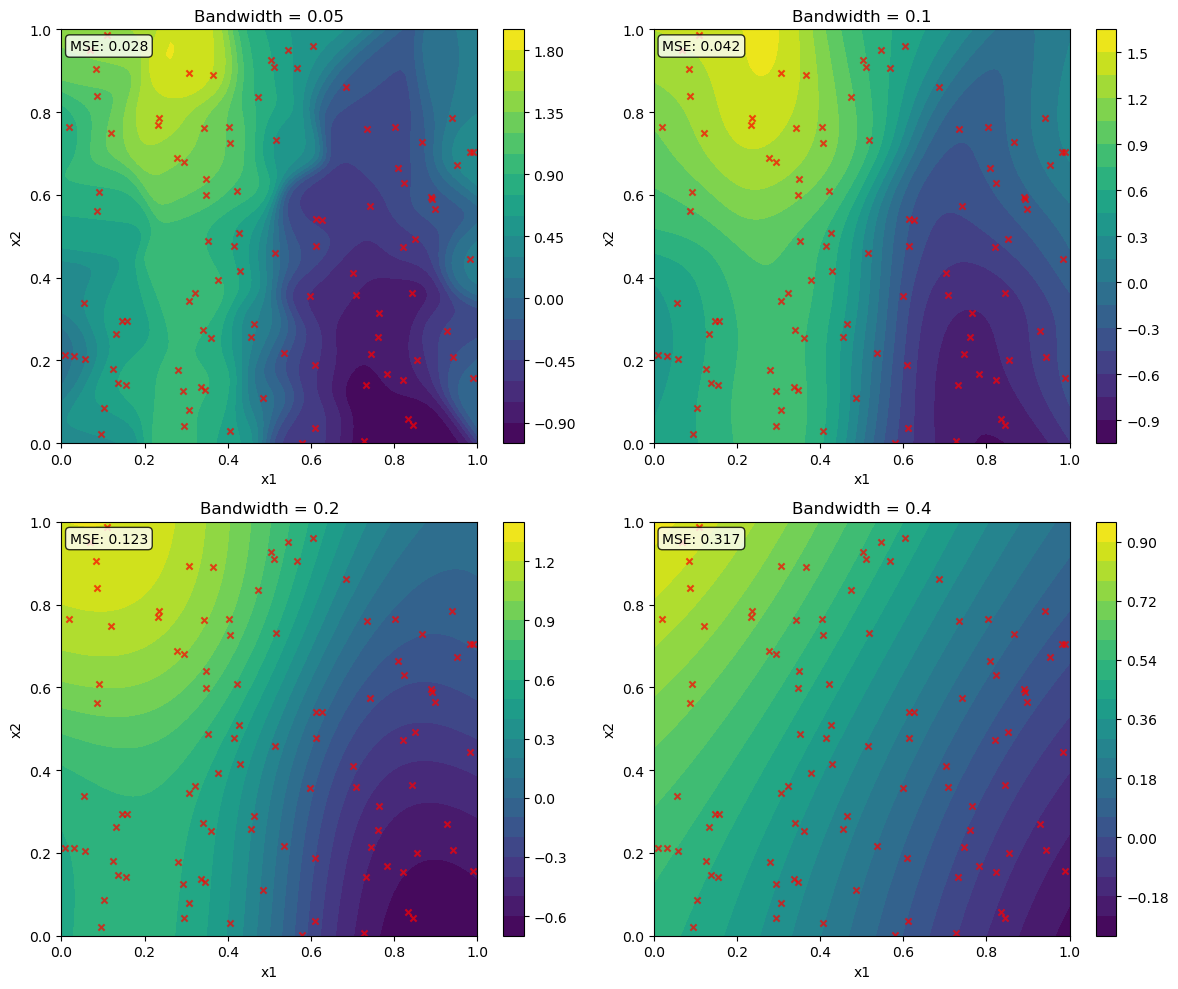

Effect of bandwidth on smoothing:
- Small bandwidth (0.05): More localized, captures fine details but may overfit
- Medium bandwidth (0.1-0.2): Good balance between smoothness and detail
- Large bandwidth (0.4): Very smooth but may underfit, loses local structure


In [3]:
# Demonstrate effect of different bandwidth values
bandwidths = [0.05, 0.1, 0.2, 0.4]
fig, axes = plt.subplots(2, 2, figsize=(12, 10))
axes = axes.flatten()

y_true = np.sin(2 * np.pi * X1) + X2*X2

for i, bw in enumerate(bandwidths):
    y_pred_bw = gaussian_kernel_smoothing(X1, X2, x1_train, x2_train, y_train, bandwidth=bw)
    
    im = axes[i].contourf(X1, X2, y_pred_bw, levels=20, cmap='viridis')
    axes[i].scatter(x1_train, x2_train, c='red', marker='x', s=20, alpha=0.7)
    axes[i].set_title(f'Bandwidth = {bw}')
    axes[i].set_xlabel('x1')
    axes[i].set_ylabel('x2')
    plt.colorbar(im, ax=axes[i])
    
    # Calculate and display MSE
    mse = np.mean((y_true - y_pred_bw)**2)
    axes[i].text(0.02, 0.95, f'MSE: {mse:.3f}', transform=axes[i].transAxes, 
                bbox=dict(boxstyle="round,pad=0.3", facecolor="white", alpha=0.8))

plt.tight_layout()
plt.show()

print("Effect of bandwidth on smoothing:")
print("- Small bandwidth (0.05): More localized, captures fine details but may overfit")
print("- Medium bandwidth (0.1-0.2): Good balance between smoothness and detail")
print("- Large bandwidth (0.4): Very smooth but may underfit, loses local structure")
